# Customer churn prediction, with a profit-optimal retention policy
**Business question:** which telecom customers are about to leave, and *who should get a retention offer* so the campaign pays for itself?

Data: IBM Telco Customer Churn sample (7,043 customers, 20 attributes).

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from sklearn.inspection import permutation_importance
df = pd.read_csv("data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)     # blank for brand-new customers
df["churn"] = (df.pop("Churn") == "Yes").astype(int)
print(f"{len(df):,} customers, churn rate {df.churn.mean():.1%}")

7,043 customers, churn rate 26.5%


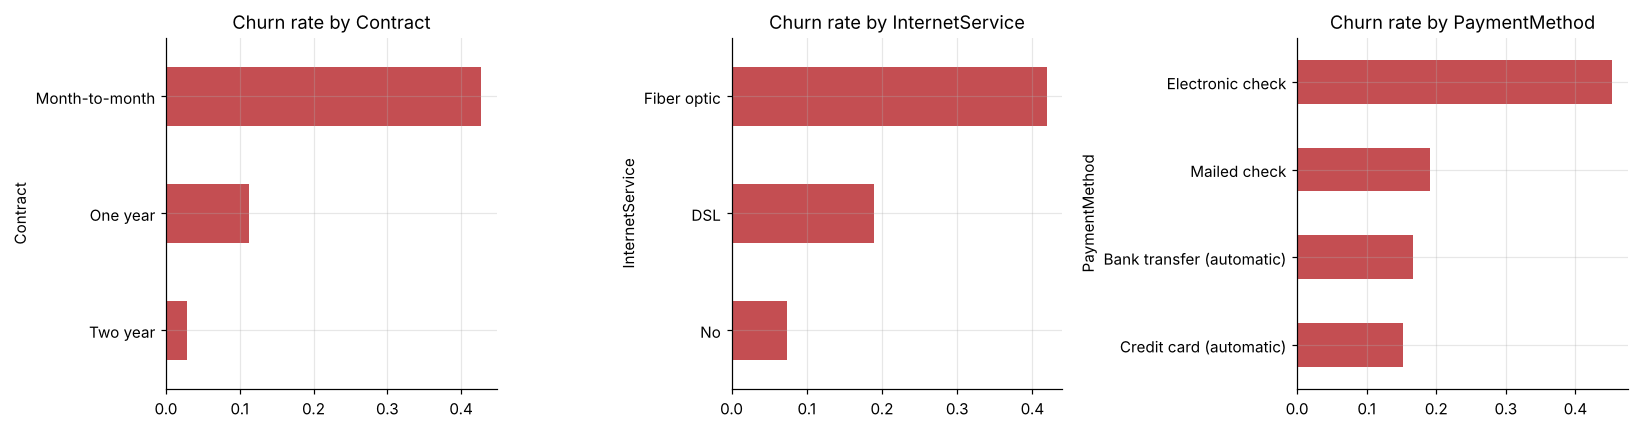

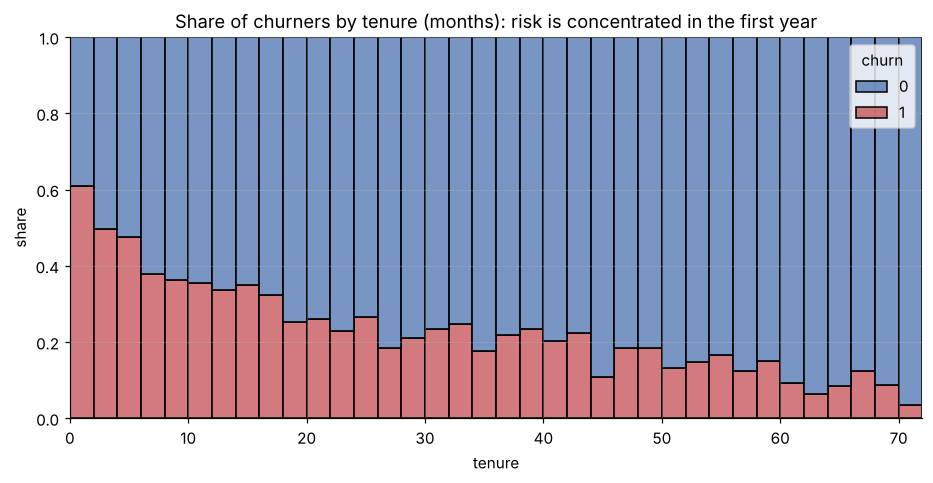

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["Contract", "InternetService", "PaymentMethod"]):
    df.groupby(col).churn.mean().sort_values().plot.barh(ax=a, color="#C44E52"); a.set_title(f"Churn rate by {col}"); a.set_xlabel("")
fig.tight_layout(); plt.savefig(IMG / "churn_drivers.png", bbox_inches="tight"); plt.show()
sns.histplot(data=df, x="tenure", hue="churn", bins=36, multiple="fill", palette=["#4C72B0", "#C44E52"])
plt.title("Share of churners by tenure (months): risk is concentrated in the first year"); plt.ylabel("share"); plt.show()

In [3]:
y = df["churn"]; X = df.drop(columns=["customerID", "churn"])
num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]; cat = [c for c in X.columns if c not in num]
prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat)])
models = {"Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=2000, C=0.5)),
          "Gradient boosting": make_pipeline(prep, HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0))}
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
scores, probs = {}, {}
for name, m in models.items():
    p_cv = cross_val_predict(m, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    m.fit(X_tr, y_tr); probs[name] = m.predict_proba(X_te)[:, 1]
    scores[name] = {"CV ROC-AUC": roc_auc_score(y_tr, p_cv), "test ROC-AUC": roc_auc_score(y_te, probs[name]),
                    "test PR-AUC": average_precision_score(y_te, probs[name])}
pd.DataFrame(scores).T.round(3)

,CV ROC-AUC,test ROC-AUC,test PR-AUC
Logistic regression,0.844,0.847,0.638
Gradient boosting,0.841,0.839,0.650


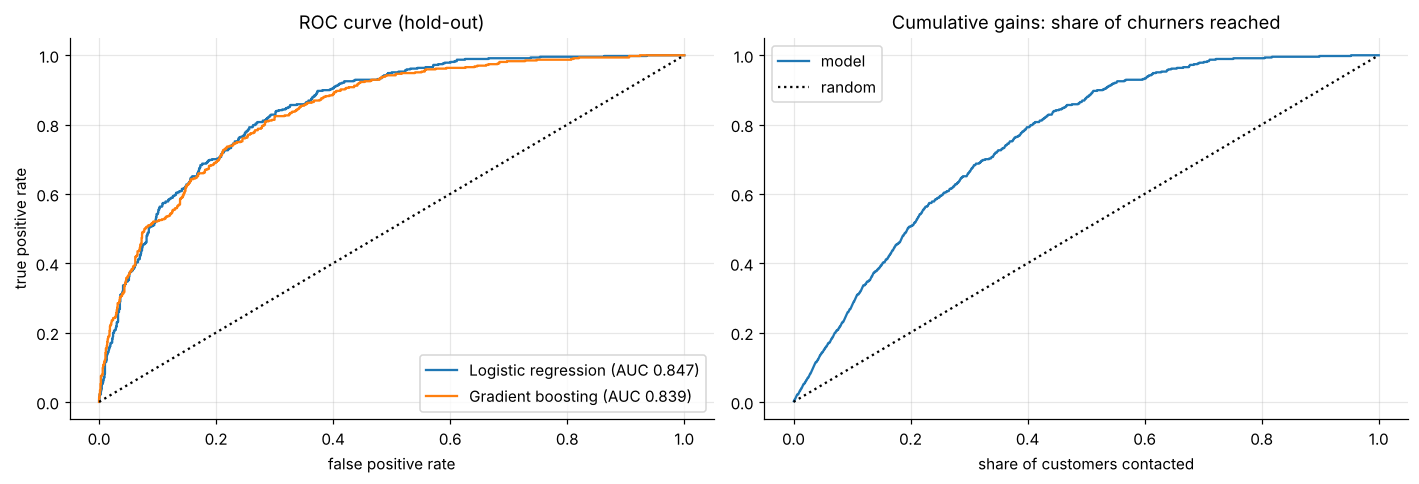

Contacting the riskiest 30% of customers reaches 66% of all churners.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC curve (hold-out)"); ax[0].legend(); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
p = probs["Logistic regression"]; order = np.argsort(-p)
captured = np.cumsum(y_te.values[order]) / y_te.sum()
ax[1].plot(np.arange(1, len(p) + 1) / len(p), captured, label="model"); ax[1].plot([0, 1], [0, 1], "k:", label="random")
ax[1].set_title("Cumulative gains: share of churners reached"); ax[1].set_xlabel("share of customers contacted"); ax[1].legend()
fig.tight_layout(); plt.savefig(IMG / "roc_gains.png", bbox_inches="tight"); plt.show()
print(f"Contacting the riskiest 30% of customers reaches {captured[int(0.3 * len(p)) - 1]:.0%} of all churners.")

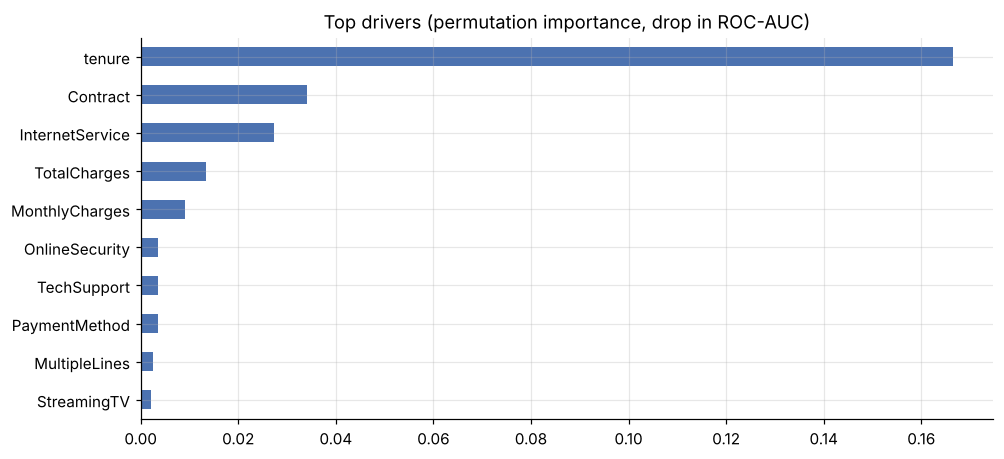

In [5]:
imp = permutation_importance(models["Logistic regression"], X_te, y_te, scoring="roc_auc", n_repeats=15, random_state=0)
pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(10).plot.barh(color="#4C72B0")
plt.title("Top drivers (permutation importance, drop in ROC-AUC)"); plt.show()

## Profit-optimal targeting
Assumptions (editable): a retention offer costs **$60** (a discount worth about one month of charges); it keeps **35%** of customers who would otherwise churn; a saved customer is worth **12 months** of their monthly charge in margin. Contacting a customer who wasn't going to leave costs the offer and gains nothing.

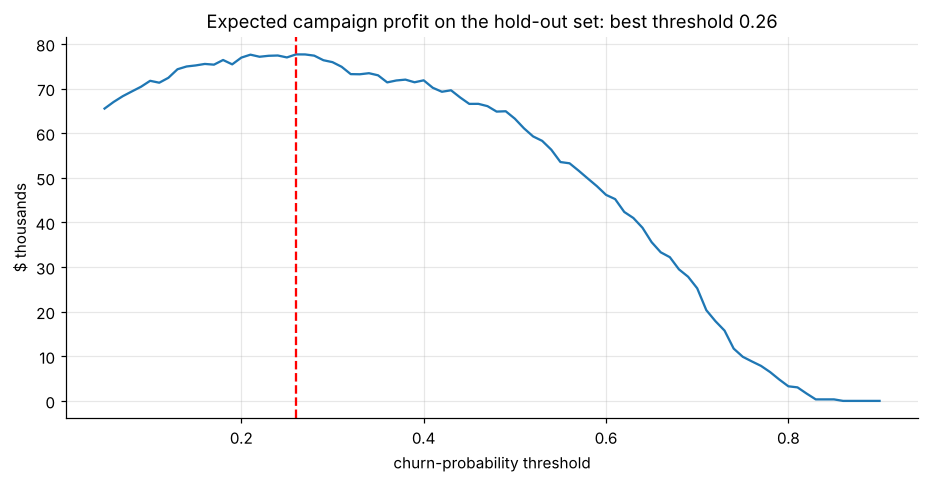

Optimal policy: contact 41% of customers -> expected profit $77,662 vs $38,465 if everyone is contacted (hold-out set of 1,761 customers).


In [6]:
OFFER_COST, SUCCESS, MONTHS = 60, 0.35, 12
p = probs["Logistic regression"]; value = X_te["MonthlyCharges"].values * MONTHS
rows = []
for t in np.linspace(0.05, 0.9, 86):
    target = p >= t
    profit = (SUCCESS * value * y_te.values - OFFER_COST)[target].sum()
    rows.append((t, target.mean(), profit))
curve = pd.DataFrame(rows, columns=["threshold", "share contacted", "expected profit"])
best = curve.loc[curve["expected profit"].idxmax()]
everyone = (SUCCESS * value * y_te.values - OFFER_COST).sum()
plt.plot(curve.threshold, curve["expected profit"] / 1000); plt.axvline(best.threshold, color="r", ls="--")
plt.title(f"Expected campaign profit on the hold-out set: best threshold {best.threshold:.2f}"); plt.xlabel("churn-probability threshold"); plt.ylabel("$ thousands")
plt.savefig(IMG / "profit_curve.png", bbox_inches="tight"); plt.show()
print(f"Optimal policy: contact {best['share contacted']:.0%} of customers -> expected profit ${best['expected profit']:,.0f} "
      f"vs ${everyone:,.0f} if everyone is contacted (hold-out set of {len(p):,} customers).")

**Recommendations**
* Churn is concentrated in **month-to-month contracts, fibre-optic internet, electronic-check payment and the first 12 months of tenure**. These are the levers for product and pricing teams.
* A simple, interpretable logistic model ranks customers as well as gradient boosting here, so the transparent model is preferred.
* Target retention offers with the **profit curve**, not a 0.5 cut-off. Contacting only the high-risk group earns more than a blanket campaign, and the threshold moves automatically if offer cost or success rate change.